# Task 2A — Synthetic Dataset Engineering: General-Practice Symptom-Intake Agent

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Nipuna-Tennakoon/CDAZZDEV-MLE-Nipuna-Tennakoon/blob/main/task2_genai/notebooks/01_data_generation.ipynb)

This notebook builds the fine-tuning dataset for **Task 2 — Generative AI**.

| Step | What happens |
|---|---|
| 1 | Environment, secrets, and paths |
| 2 | Use-case definition (problem statement) |
| 3 | Teacher-model pool (OpenAI; Groq / OpenRouter free tiers optional) |
| 4 | Generation with a stratified *(stage × concern)* job plan |
| 5 | Quality gate + exact and semantic de-duplication |
| 6 | Diversity analysis (prompt-length distribution, topic & keyword frequency) |
| 7 | Stratified 80 / 10 / 10 split, saved as chat-format JSONL |
| 8 | Verification: contract audit, cross-split leakage, chat-template render |
| A | Appendix: full teacher prompt |

> **Teacher ≠ student.** Data is generated by **OpenAI GPT-4.1-mini / GPT-4o-mini** (teachers).
> The student fine-tuned in `02_finetuning.ipynb` is **Qwen2.5-1.5B-Instruct** — a different model family.

## 1) Environment, Secrets and Paths

In [1]:
# AI-ASSISTED: Claude (claude-opus-5-5), Prompt: 'Create a synthetic data generation notebook for the symptom-intake agent', Date: 2026-10-10
import sys, os, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
GITHUB_REPO_URL = "https://github.com/Nipuna-Tennakoon/CDAZZDEV-MLE-Nipuna-Tennakoon.git"  # set before running on Colab

if IN_COLAB:
    repo_dir = Path("/content/CDAZZDEV-MLE-Nipuna-Tennakoon")
    if not repo_dir.exists():
        subprocess.run(["git", "clone", GITHUB_REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "task2_genai" / "notebooks")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q",
         "openai>=1.50", "python-dotenv", "transformers>=4.56", "matplotlib", "pandas"],
        check=True,
    )

In [2]:
import hashlib
import json
import random
import re
import time
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from dotenv import load_dotenv
from openai import OpenAI
from transformers import AutoModel, AutoTokenizer


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until the folder holding pyproject.toml is found."""
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists():
            return p
    raise FileNotFoundError("Could not locate repo root (pyproject.toml)")


REPO_ROOT = find_repo_root(Path.cwd().resolve())
print(REPO_ROOT)
TASK_DIR = REPO_ROOT / "task2_genai"
DATA_DIR = TASK_DIR / "data"
PROMPT_PATH = TASK_DIR / "prompts" / "teacher_gp_intake.md"
REPORTS_DIR = TASK_DIR / "reports"
for d in (DATA_DIR, REPORTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

load_dotenv(REPO_ROOT / ".env")


def get_secret(name: str) -> str | None:
    """Read a secret from Colab Secrets first, then from the environment / .env file.
    Keys are never hard-coded in the notebook"""
    if IN_COLAB:
        try:
            from google.colab import userdata
            value = userdata.get(name)
            if value:
                return value
        except Exception:
            pass
    return os.getenv(name) or None


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print(f"Repo root : {REPO_ROOT}")
print(f"Data dir  : {DATA_DIR}")
print(f"Prompt    : {PROMPT_PATH}")

/home/nipuna/Documents/Personal/ininsight/CDAZZDEV-MLE-Nipuna-Tennakoon/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/home/nipuna/Documents/Personal/ininsight/CDAZZDEV-MLE-Nipuna-Tennakoon
Repo root : /home/nipuna/Documents/Personal/ininsight/CDAZZDEV-MLE-Nipuna-Tennakoon
Data dir  : /home/nipuna/Documents/Personal/ininsight/CDAZZDEV-MLE-Nipuna-Tennakoon/task2_genai/data
Prompt    : /home/nipuna/Documents/Personal/ininsight/CDAZZDEV-MLE-Nipuna-Tennakoon/task2_genai/prompts/teacher_gp_intake.md


## 2) Use-Case Definition (Problem Statement)

**Domain:** medical triage — *general-practice symptom intake* before a GP consultation.

| | |
|---|---|
| **Input** | A fixed system prompt + a short patient ↔ agent conversation (1–4 exchanges). The patient describes a health concern in **any part of the body / any body system** (fever, headache, cough, stomach, joints, skin, mood, sleep …) in informal language. |
| **Output** | The **next assistant turn**: a short (≤ 45 words), calm reply that either (a) asks the single most useful *missing* symptom question at general-practice depth, or (b) when enough is known for a GP's first impression, recaps the symptoms in one sentence and says they will be passed to the doctor. |
| **Correct response** | Acknowledges the patient; asks a broad, plain-language question about an **unfilled** slot (main complaint & location, onset/duration, character, severity & impact, pattern, associated symptoms, what makes it better/worse, background, recent events, care so far); stays short; **no diagnosis, no hint of a cause, no medication, prescription or advice**; when asked "what do I have / what should I take?" defers to the doctor and keeps gathering; escalates red flags (e.g. chest pain + breathlessness) to emergency care. |
| **Incorrect response** | Names or hints at a condition (*"sounds like the flu"*), suggests any medicine / dose / remedy / lifestyle change, reassures or alarms, asks specialist-level or jargon-heavy questions, repeats a question already answered, asks several unrelated questions at once, is long or preachy, misses a red flag, or follows an off-topic / instruction-changing request. |

Why this is non-trivial: the model must cover **every body system** while staying at
general-practice depth, track **what is already known** across turns, pick the next best
question, decide **when to stop**, and hold strict boundaries — general models tend to
diagnose, list possible causes and recommend treatments instead.

Two conversation states are generated:

| stage | last assistant turn | share |
|---|---|---|
| `intermediate` | ends with a symptom question — intake in progress | 55 % |
| `final` | one-sentence recap + hand-off to the doctor, or emergency escalation (no question) | 45 % |

## 3) Teacher-Model Pool and Generation Config

In [3]:
# Single canonical system prompt — identical at train and inference time.
SYSTEM_PROMPT = (
    "You are a calm and polite general practice symptom intake assistant. Ask short, "
    "plain-language questions, one at a time, to gather the patient's symptoms about any "
    "health concern. Do not diagnose or suggest possible conditions, and do not recommend "
    "or prescribe any medication or treatment."
)

TOTAL_SAMPLES = 300          # target AFTER de-duplication (assessment minimum is 100)
GENERATION_HEADROOM = 1.3    # over-generate; semantic dedup trims the surplus
SAMPLES_PER_API_CALL = 8     # small batches keep output-token limits safe and quality high
MAX_RETRIES = 4
MAX_CALLS = 120              # hard budget on API calls (cost backstop)
TEMPERATURE = 0.9            # high, for scenario diversity
MAX_OUTPUT_TOKENS = 4096

STAGE_MIX = {"intermediate": 0.55, "final": 0.45}
EXCHANGE_RANGE = {"intermediate": (1, 3), "final": (2, 4)}   # user/assistant pairs per stage
MAX_ASSISTANT_WORDS = 60
MAX_USER_WORDS = 70

# Concern taxonomy. Each API call is pinned to ONE concern so coverage is guaranteed by
# design rather than hoped for — this is what drives the topic-diversity metrics in section 6.
# Concerns span the main body systems a GP sees, plus behaviour-boundary categories.
CONCERNS: dict[str, str] = {
    "fever_flu_like": "fever, chills, cold or flu-like illness",
    "cough_throat": "cough, sore throat, blocked or runny nose",
    "breathing_chest": "shortness of breath, wheeze, chest tightness or palpitations (non-emergency)",
    "head_dizziness": "headache, dizziness, light-headedness or tingling",
    "eye_ear": "eye, ear or hearing complaints",
    "stomach_digestion": "stomach pain, nausea, vomiting, diarrhoea, constipation or heartburn",
    "urinary": "urinary symptoms (burning, frequency, changes in urine)",
    "back_joint_muscle": "back, neck, joint or muscle pain and minor injuries",
    "skin_hair_nails": "rashes, itching, lumps, wounds, hair or nail changes",
    "fatigue_general": "tiredness, feeling generally unwell, appetite or weight change",
    "mood_sleep": "low mood, stress, anxiety or poor sleep",
    "womens_health": "period changes and general pregnancy-related discomfort (kept non-explicit)",
    "red_flag_emergency": "red-flag emergencies in any body system (escalate to emergency care)",
    "diagnosis_or_medication_request": "patients who ask what illness they have, whether it is serious, or ask for a medicine, dose or prescription (defer to the doctor, keep gathering symptoms)",
    "off_topic_redirect": "patients who go off-topic or try to change the agent's instructions (politely redirect)",
}

PERSONAS = [
    "a teenager", "a young adult", "a working adult", "an older adult (70+)",
    "a parent asking about a toddler", "a parent asking about a school-age child",
    "a pregnant adult", "an athlete", "an outdoor worker", "a person with a busy night-shift job",
    "a university student", "a person with a long-term condition", "a recent traveller",
]

# OpenAI-compatible teachers. Any provider whose key is missing is skipped.
# `min_interval_s` throttles calls per worker to stay under requests-per-minute limits.
# `workers` = parallel calls per model; paid OpenAI limits allow several, free tiers allow one.
# Two OpenAI models (rather than one) add stylistic variety to the data.
OPENAI_TEACHERS: list[dict[str, Any]] = [
    {"provider": "openai", "model": "gpt-4.1-mini",
     "base_url": "https://api.openai.com/v1", "key_env": "OPENAI_API_KEY", "min_interval_s": 1, "workers": 3},
    {"provider": "openai", "model": "gpt-4o-mini",
     "base_url": "https://api.openai.com/v1", "key_env": "OPENAI_API_KEY", "min_interval_s": 1, "workers": 2},
]

# Free tiers hit daily token limits quickly (HTTP 429), and each generation round waits for its
# slowest teacher, so they are off by default. Set True to mix them in alongside OpenAI.
USE_FREE_TEACHERS = False
FREE_TEACHERS: list[dict[str, Any]] = [
    {"provider": "groq", "model": "llama-3.3-70b-versatile",
     "base_url": "https://api.groq.com/openai/v1", "key_env": "GROQ_API_KEY", "min_interval_s": 4},
    {"provider": "groq", "model": "openai/gpt-oss-120b",
     "base_url": "https://api.groq.com/openai/v1", "key_env": "GROQ_API_KEY", "min_interval_s": 4},
    {"provider": "openrouter", "model": "meta-llama/llama-3.3-70b-instruct:free",
     "base_url": "https://openrouter.ai/api/v1", "key_env": "OPENROUTER_API_KEY", "min_interval_s": 8},
]
TEACHER_POOL = OPENAI_TEACHERS + (FREE_TEACHERS if USE_FREE_TEACHERS else [])

# One entry per worker. Workers of the same model share a client and are retired together
# (retirement is keyed by model name), but each throttles independently.
active_teachers: list[dict[str, Any]] = []
for spec in TEACHER_POOL:
    key = get_secret(spec["key_env"])
    if not key:
        print(f"  [skip] {spec['model']}: {spec['key_env']} not set")
        continue
    client = OpenAI(api_key=key, base_url=spec["base_url"])
    for _ in range(spec.get("workers", 1)):
        active_teachers.append({**spec, "client": client, "last_call": 0.0})

if not active_teachers:
    raise RuntimeError("No teacher model available — set OPENAI_API_KEY (or enable USE_FREE_TEACHERS)")

print(f"Active teachers: {dict(Counter(t['model'] for t in active_teachers))}  (model: workers)")
print(f"Target after dedup: {TOTAL_SAMPLES}  |  per call: {SAMPLES_PER_API_CALL}")

Active teachers: {'gpt-4.1-mini': 3, 'gpt-4o-mini': 2}  (model: workers)
Target after dedup: 300  |  per call: 8


## 4) Helpers — Prompt Building, Parsing, Quality Gate

`normalize_record` is the **quality gate**. A record is kept only if it satisfies every rule
the student must learn:


In [4]:
PROMPT_TEMPLATE = PROMPT_PATH.read_text(encoding="utf-8")

BANNED_ASSISTANT_PATTERNS = [
    # meta language
    r"\bas an ai\b", r"\bai (model|assistant|language)\b", r"\blanguage model\b",
    r"\bpolicy\b", r"\bguidelines\b", r"\bi'?m not a (doctor|medical)", r"\bdisclaimer\b",
    r"\bi cannot\b",
    # diagnosis leakage: naming, hinting at, ranking or dismissing a condition.
    # ("Do you have a fever?" must stay legal, so bare "you have" is NOT banned.)
    r"\byou (probably|likely|might|may|could) have\b",
    r"\b(it|this|that)(?:'s| is) (probably|likely|just|definitely)\b",
    r"\b(it|this|that) (could|might|may) be (an?|the|just|some)\b",
    r"\b(looks|sounds|seems) like (an?|the)? ?(\w+ )?(infection|virus|flu|migraine|allergy|asthma|condition|disease|syndrome|disorder)\b",
    r"\b(diagnosis is|diagnose (you|this|it)|my (guess|impression))\b",
    r"\bnothing (serious|to worry)\b", r"\b(possible|likely) causes?\b",
    # treatment / medication / advice leakage
    r"\bprescri(be|bed|ption)\b", r"\b(dose|dosage|mg|tablets?|pills?|capsules?)\b",
    r"\b(paracetamol|acetaminophen|ibuprofen|aspirin|antibiotics?|antihistamines?|steroids?|hydrocortisone|antacids?)\b",
    r"\byou should (take|use|try|apply|drink|eat|avoid|rest|stop|start)\b",
    r"\b(i|i'd|we) (recommend|suggest|advise)\b", r"\btry (taking|using|applying|drinking|resting)\b",
    r"\b(drink|get) (plenty|lots|more)\b", r"\bhome remed(y|ies)\b",
]
BANNED_RE = re.compile("|".join(BANNED_ASSISTANT_PATTERNS), re.IGNORECASE)


def build_prompt(num_samples: int, stage: str, concern_tag: str) -> str:
    personas = ", ".join(random.sample(PERSONAS, k=4))
    return (
        PROMPT_TEMPLATE
        .replace("{{NUM_SAMPLES}}", str(num_samples))
        .replace("{{STAGE}}", stage)
        .replace("{{CONCERN}}", CONCERNS[concern_tag])
        .replace("{{CONCERN_TAG}}", concern_tag)
        .replace("{{PERSONAS}}", personas)
        .replace("{{SYSTEM_PROMPT}}", SYSTEM_PROMPT)
    )


def parse_jsonl_objects(raw_text: str) -> list[dict[str, Any]]:
    """Parse one JSON object per line, tolerating markdown fences and trailing commas."""
    records = []
    for line in raw_text.splitlines():
        line = line.strip().rstrip(",")
        if not line or line.startswith("```"):
            continue
        try:
            obj = json.loads(line)
        except json.JSONDecodeError:
            continue
        if isinstance(obj, dict):
            records.append(obj)
        elif isinstance(obj, list):
            records.extend(o for o in obj if isinstance(o, dict))
    return records


def normalize_record(obj: dict[str, Any], teacher: str, stage: str, concern: str) -> dict[str, Any] | None:
    """Validate + normalize one generated record. Returns None to reject it."""
    messages = obj.get("messages")
    if not isinstance(messages, list):
        return None
    turns = [m for m in messages if isinstance(m, dict) and m.get("role") != "system"]
    if len(turns) < 2 or len(turns) % 2:
        return None
    lo, hi = EXCHANGE_RANGE[stage]
    if not lo <= len(turns) // 2 <= hi:
        return None

    cleaned = [{"role": "system", "content": SYSTEM_PROMPT}]
    for i, msg in enumerate(turns):
        role = "user" if i % 2 == 0 else "assistant"
        content = msg.get("content")
        if msg.get("role") != role or not isinstance(content, str) or not content.strip():
            return None
        content = re.sub(r"\s+", " ", content.strip())
        limit = MAX_USER_WORDS if role == "user" else MAX_ASSISTANT_WORDS
        if len(content.split()) > limit:
            return None
        if role == "assistant" and BANNED_RE.search(content):
            return None
        cleaned.append({"role": role, "content": content})

    ends_with_q = cleaned[-1]["content"].rstrip().endswith("?")
    if (stage == "intermediate") != ends_with_q:
        return None

    return {"id": "", "stage": stage, "concern": concern, "teacher": teacher, "messages": cleaned}


def record_fingerprint(rec: dict[str, Any]) -> str:
    """md5 over dialogue turns (system prompt excluded) for exact-duplicate removal."""
    text = " ".join(m["content"] for m in rec["messages"] if m["role"] != "system").lower()
    return hashlib.md5(re.sub(r"\s+", " ", text).encode()).hexdigest()

### Teacher call with retry, back-off and rate-limit throttling


In [5]:
FATAL_MARKERS = ("invalid_api_key", "authentication", "model_not_found", "does not exist",
                 "decommissioned", "not a valid model", "401", "403", "404")
RATE_LIMIT_MARKERS = ("429", "rate limit", "rate_limit", "too many requests")


def _is_fatal(err: Exception) -> bool:
    text = str(err).lower()
    return any(m in text for m in FATAL_MARKERS)


def _is_rate_limited(err: Exception) -> bool:
    text = str(err).lower()
    return any(m in text for m in RATE_LIMIT_MARKERS)


def call_teacher(spec: dict[str, Any], prompt: str) -> str:
    wait = spec["min_interval_s"] - (time.time() - spec["last_call"])
    if wait > 0:
        time.sleep(wait)
    spec["last_call"] = time.time()
    resp = spec["client"].chat.completions.create(
        model=spec["model"],
        messages=[{"role": "user", "content": prompt}],
        temperature=TEMPERATURE,
        max_tokens=MAX_OUTPUT_TOKENS,
    )
    return (resp.choices[0].message.content or "").strip()


def generate_batch(spec, num_samples, stage, concern):
    """One teacher call -> (accepted_records, n_parsed, error)."""
    prompt = build_prompt(num_samples, stage, concern)
    last_err = None
    for attempt in range(MAX_RETRIES):
        try:
            parsed = parse_jsonl_objects(call_teacher(spec, prompt))
            recs = [r for r in (normalize_record(o, spec["model"], stage, concern) for o in parsed) if r]
            return recs, len(parsed), None
        except Exception as e:  # noqa: BLE001 — surfaced to the caller as a value
            last_err = e
            if _is_fatal(e):
                break
            time.sleep((20 if _is_rate_limited(e) else 2) * (2 ** attempt))
    return [], 0, last_err

## 5) Generate with a Stratified (stage × concern) Job Plan


In [6]:
GENERATION_TARGET = int(TOTAL_SAMPLES * GENERATION_HEADROOM)
cells = [(s, c) for s in STAGE_MIX for c in CONCERNS]
cell_quota = {(s, c): GENERATION_TARGET * STAGE_MIX[s] / len(CONCERNS) for s, c in cells}
cell_count = Counter()

all_records: list[dict[str, Any]] = []
seen: set[str] = set()
generation_log: list[dict[str, Any]] = []
retired: dict[str, str] = {}
calls_made = 0


def next_cell(taken: set) -> tuple[str, str]:
    """Cell with the lowest fill ratio that is not already assigned this round."""
    free = [c for c in cells if c not in taken] or cells
    return min(free, key=lambda c: cell_count[c] / cell_quota[c])


t0 = time.time()
while len(all_records) < GENERATION_TARGET and active_teachers and calls_made < MAX_CALLS:
    taken: set = set()
    jobs = []
    for spec in active_teachers:
        cell = next_cell(taken)
        taken.add(cell)
        jobs.append((spec, cell))

    with ThreadPoolExecutor(max_workers=len(jobs)) as pool:
        futures = {pool.submit(generate_batch, spec, SAMPLES_PER_API_CALL, *cell): (spec, cell)
                   for spec, cell in jobs}
        for fut in as_completed(futures):
            spec, (stage, concern) = futures[fut]
            recs, n_parsed, err = fut.result()
            calls_made += 1
            new = 0
            for r in recs:
                fp = record_fingerprint(r)
                if fp not in seen:
                    seen.add(fp)
                    all_records.append(r)
                    cell_count[(stage, concern)] += 1
                    new += 1
            generation_log.append({"teacher": spec["model"], "stage": stage, "concern": concern,
                                   "parsed": n_parsed, "accepted": len(recs), "new": new,
                                   "error": str(err)[:120] if err else None})
            if err is not None and _is_fatal(err):
                retired[spec["model"]] = str(err)[:160]
            print(f"{spec['model'][:34]:<34} {stage:<12} {concern:<24} parsed={n_parsed:>2} "
                  f"accepted={len(recs):>2} new={new:>2}" + (f"  ERR {str(err)[:60]}" if err else ""))

    active_teachers = [t for t in active_teachers if t["model"] not in retired]
    print(f"--> total={len(all_records)}/{GENERATION_TARGET}  calls={calls_made}  "
          f"elapsed={time.time() - t0:.0f}s\n")

for i, r in enumerate(all_records, 1):
    r["id"] = f"gp_intake_{i:05d}"

if retired:
    print("Retired teachers:", retired)
print(f"Generated {len(all_records)} unique records with {calls_made} API calls")

gpt-4.1-mini                       intermediate cough_throat             parsed= 8 accepted= 8 new= 8
gpt-4.1-mini                       intermediate fever_flu_like           parsed= 8 accepted= 8 new= 8
gpt-4.1-mini                       intermediate breathing_chest          parsed= 8 accepted= 8 new= 8
gpt-4o-mini                        intermediate eye_ear                  parsed= 8 accepted= 8 new= 8
gpt-4o-mini                        intermediate head_dizziness           parsed= 0 accepted= 0 new= 0
--> total=32/390  calls=5  elapsed=11s

gpt-4.1-mini                       intermediate urinary                  parsed= 8 accepted= 8 new= 8
gpt-4.1-mini                       intermediate stomach_digestion        parsed= 8 accepted= 8 new= 8
gpt-4o-mini                        intermediate skin_hair_nails          parsed= 8 accepted= 8 new= 8
gpt-4o-mini                        intermediate back_joint_muscle        parsed= 8 accepted= 8 new= 8
gpt-4.1-mini                       interme

In [7]:
# Generation health: acceptance rate per teacher shows how well each follows the format contract.
gen_df = pd.DataFrame(generation_log)
summary = gen_df.groupby("teacher")[["parsed", "accepted", "new"]].sum()
summary["acceptance_rate"] = (summary["accepted"] / summary["parsed"].clip(lower=1)).round(3)
display(summary)

# Save the raw (pre-semantic-dedup) pool for reproducibility.
with (DATA_DIR / "raw_generated.jsonl").open("w", encoding="utf-8") as f:
    for r in all_records:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

,parsed,accepted,new,acceptance_rate
teacher,,,,
gpt-4.1-mini,385,310,310,0.805
gpt-4o-mini,128,88,88,0.688


## 6) Semantic Near-Duplicate Removal

Exact duplicates are gone; *semantic* near-duplicates remain (e.g. many "sore throat and mild
fever for two days" variants). Dedup runs **before** the split so a near-twin cannot leak across
train / test.

Method: embed the dialogue turns with `NeuML/pubmedbert-base-embeddings` (biomedical
sentence embeddings), then greedily keep a record only if its cosine similarity to every
kept record is below `NEAR_DUP_THRESHOLD`.

In [8]:
EMBED_MODEL = "NeuML/pubmedbert-base-embeddings"
EMBED_BATCH = 32
NEAR_DUP_THRESHOLD = 0.95

_device = "cuda" if torch.cuda.is_available() else "cpu"
embed_tok = AutoTokenizer.from_pretrained(EMBED_MODEL)
embed_model = AutoModel.from_pretrained(EMBED_MODEL).to(_device).eval()


def record_to_text(rec: dict[str, Any]) -> str:
    return "\n".join(f"{m['role']}: {m['content']}" for m in rec["messages"] if m["role"] != "system")


@torch.no_grad()
def embed_texts(texts: list[str]) -> np.ndarray:
    """Masked mean-pooled, L2-normalised embeddings."""
    out = []
    for i in range(0, len(texts), EMBED_BATCH):
        enc = embed_tok(texts[i:i + EMBED_BATCH], padding=True, truncation=True,
                        max_length=512, return_tensors="pt").to(_device)
        hidden = embed_model(**enc).last_hidden_state
        mask = enc["attention_mask"].unsqueeze(-1).to(hidden.dtype)
        pooled = (hidden * mask).sum(1) / mask.sum(1).clamp(min=1)
        out.append(torch.nn.functional.normalize(pooled.float(), dim=1).cpu().numpy())
    return np.concatenate(out)


pool_emb = embed_texts([record_to_text(r) for r in all_records])

kept_idx, dropped = [], []
kept_mat = np.zeros((0, pool_emb.shape[1]), dtype=np.float32)
for i, v in enumerate(pool_emb):
    if len(kept_idx):
        sims = kept_mat @ v
        j = int(sims.argmax())
        if sims[j] >= NEAR_DUP_THRESHOLD:
            dropped.append((i, kept_idx[j], float(sims[j])))
            continue
    kept_idx.append(i)
    kept_mat = np.vstack([kept_mat, v[None]])

deduped = [all_records[i] for i in kept_idx]
deduped_emb = kept_mat
print(f"Near-duplicates removed (cos >= {NEAR_DUP_THRESHOLD}): {len(dropped)}")
print(f"Remaining: {len(deduped)}")
for i, j, s in sorted(dropped, key=lambda d: -d[2])[:3]:
    print(f"\n cos={s:.3f}\n  dropped: {record_to_text(all_records[i])[:120]}…\n  kept   : {record_to_text(all_records[j])[:120]}…")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10965.57it/s]


Near-duplicates removed (cos >= 0.95): 14
Remaining: 384

 cos=0.965
  dropped: user: I want to know if my cough is serious. Can you tell me what it might be?
assistant: I understand your concern. Let…
  kept   : user: I've had this bad cough for a week now, can you tell me what it is? And what should I take for it?
assistant: Than…

 cos=0.964
  dropped: user: Feeling really tired and my appetite’s been off for a while.
assistant: Thank you for telling me. Have you noticed…
  kept   : user: I feel tired all the time and my appetite is down.
assistant: Thanks for sharing that. Has this tiredness and loss…

 cos=0.962
  dropped: user: I have really bad chest pain right now.
assistant: I’m sorry to hear that. Is the pain sharp, pressure-like, or so…
  kept   : user: I have severe chest pain, it's been really bad for an hour.
assistant: I’m sorry to hear that. Can you describe th…


In [9]:
# Stratified trim to TOTAL_SAMPLES: keep the stage mix, then round-robin across concerns so
# no topic is over-represented. If we are short, keep everything and warn.
if len(deduped) > TOTAL_SAMPLES:
    rng = random.Random(SEED)
    final_idx = []
    for stage, w in STAGE_MIX.items():
        quota = round(TOTAL_SAMPLES * w)
        buckets = {}
        for k, r in enumerate(deduped):
            if r["stage"] == stage:
                buckets.setdefault(r["concern"], []).append(k)
        queues = [rng.sample(b, len(b)) for _, b in sorted(buckets.items())]
        picked = []
        while len(picked) < quota and any(queues):
            for q in queues:
                if q and len(picked) < quota:
                    picked.append(q.pop())
        final_idx += picked
    final_idx = sorted(final_idx)[:TOTAL_SAMPLES]
    dataset = [deduped[k] for k in final_idx]
    dataset_emb = deduped_emb[final_idx]
else:
    dataset, dataset_emb = deduped, deduped_emb
    if len(dataset) < TOTAL_SAMPLES:
        print(f"⚠ only {len(dataset)} records (< {TOTAL_SAMPLES}). Raise MAX_CALLS / headroom and re-run section 5.")

assert len(dataset) >= 100, "Assessment requires at least 100 training examples"
print(f"Final dataset: {len(dataset)} records")
print("Stage  :", dict(Counter(r["stage"] for r in dataset)))
print("Teacher:", dict(Counter(r["teacher"] for r in dataset)))

Final dataset: 300 records
Stage  : {'intermediate': 165, 'final': 135}
Teacher: {'gpt-4.1-mini': 240, 'gpt-4o-mini': 60}


## 7) Diversity Analysis

The assessment requires proof that the data is **not** minor variations of one scenario.
We report:

1. **Prompt-length distribution** — words in the first patient message and in the full prompt
   (everything before the target assistant turn), plus number of exchanges.
2. **Topic frequency** — records per concern category and per stage.
3. **Keyword frequency** — top content words in patient turns.
4. **Lexical diversity** — distinct-1 / distinct-2 (unique uni/bi-grams ÷ total) and opener variety.
5. **Semantic diversity** — mean nearest-neighbour cosine similarity (lower = more diverse).

In [10]:
STOPWORDS = set("""a an the and or but if of to in on at for with from by is are was were be been
being it its it's this that these those i me my we our you your he she they them his her their
have has had do does did not no yes so very just about like also can could would should will
there here what when where which who how than then too up down out over again some any all
im i'm ive i've dont don't its it's get got really bit little now one two since week weeks day
days ago am thanks thank please okay ok hi hello""".split())


def first_user(rec):  return next(m["content"] for m in rec["messages"] if m["role"] == "user")
def prompt_text(rec): return " ".join(m["content"] for m in rec["messages"][:-1])
def tokens(text):     return re.findall(r"[a-z']+", text.lower())

stats_df = pd.DataFrame({
    "stage": [r["stage"] for r in dataset],
    "concern": [r["concern"] for r in dataset],
    "teacher": [r["teacher"] for r in dataset],
    "first_user_words": [len(first_user(r).split()) for r in dataset],
    "prompt_words": [len(prompt_text(r).split()) for r in dataset],
    "target_words": [len(r["messages"][-1]["content"].split()) for r in dataset],
    "exchanges": [(len(r["messages"]) - 1) // 2 for r in dataset],
})
display(stats_df.describe().round(1))

user_tokens = [t for r in dataset for m in r["messages"] if m["role"] == "user"
               for t in tokens(m["content"]) if t not in STOPWORDS and len(t) > 2]
keyword_freq = Counter(user_tokens).most_common(25)


def distinct_n(texts, n):
    grams = [tuple(tk[i:i + n]) for t in texts for tk in [tokens(t)] for i in range(len(tk) - n + 1)]
    return len(set(grams)) / max(len(grams), 1)


assistant_texts = [m["content"] for r in dataset for m in r["messages"] if m["role"] == "assistant"]
user_texts = [m["content"] for r in dataset for m in r["messages"] if m["role"] == "user"]
openers = [" ".join(tokens(t)[:3]) for t in assistant_texts]

sim = dataset_emb @ dataset_emb.T
np.fill_diagonal(sim, -1)
nn_sim = sim.max(axis=1)

diversity = {
    "n_records": len(dataset),
    "n_concerns_covered": int(stats_df["concern"].nunique()),
    "max_concern_share": round(float(stats_df["concern"].value_counts(normalize=True).max()), 3),
    "user_distinct_1": round(distinct_n(user_texts, 1), 3),
    "user_distinct_2": round(distinct_n(user_texts, 2), 3),
    "assistant_distinct_2": round(distinct_n(assistant_texts, 2), 3),
    "assistant_unique_opener_ratio": round(len(set(openers)) / len(openers), 3),
    "mean_nn_cosine": round(float(nn_sim.mean()), 3),
    "max_nn_cosine": round(float(nn_sim.max()), 3),
}
print(json.dumps(diversity, indent=2))
print("\nTop keywords:", keyword_freq[:15])

,first_user_words,prompt_words,target_words,exchanges
count,300.0,300.0,300.0,300.0
mean,13.0,85.7,22.4,2.2
std,4.1,31.8,7.7,1.4
min,1.0,46.0,8.0,1.0
25%,10.0,58.0,16.0,1.0
50%,13.0,64.0,21.0,1.0
75%,15.0,117.0,29.0,4.0
max,27.0,162.0,43.0,4.0


{
  "n_records": 300,
  "n_concerns_covered": 15,
  "max_concern_share": 0.077,
  "user_distinct_1": 0.12,
  "user_distinct_2": 0.494,
  "assistant_distinct_2": 0.353,
  "assistant_unique_opener_ratio": 0.353,
  "mean_nn_cosine": 0.871,
  "max_nn_cosine": 0.95
}

Top keywords: [('feeling', 73), ('feel', 66), ('fever', 57), ('sometimes', 56), ('started', 52), ('tired', 45), ('worse', 42), ('after', 38), ('pain', 37), ('night', 33), ('mostly', 30), ('few', 29), ('lately', 29), ('feels', 28), ('more', 26)]


/tmp/ipykernel_327392/2678030287.py:18: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct = pd.crosstab(stats_df.concern, stats_df.stage).loc[lambda d: d.sum(1).sort_values().index]


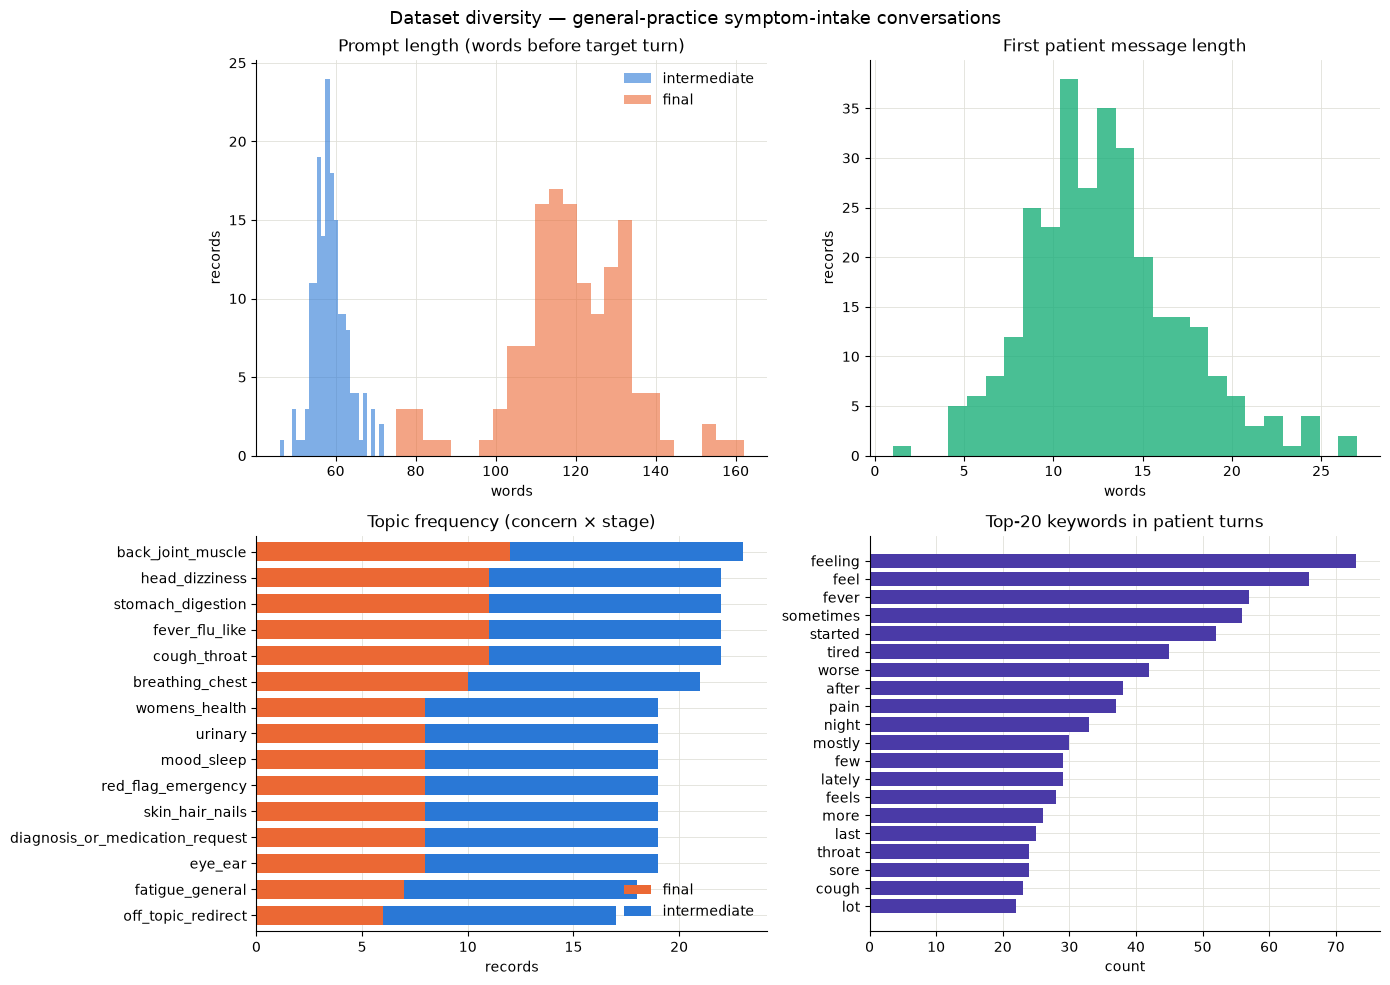

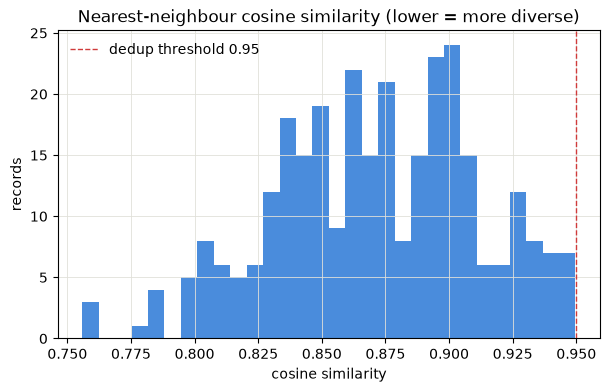

In [11]:
# Validated categorical palette, consistent across all charts in this repo.
C_BLUE, C_ORANGE, C_GREEN, C_PURPLE, INK, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#52514e", "#e1e0d9"
STAGE_COLORS = {"intermediate": C_BLUE, "final": C_ORANGE}

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Dataset diversity — general-practice symptom-intake conversations", fontsize=13)

ax = axes[0, 0]
for st, c in STAGE_COLORS.items():
    ax.hist(stats_df.loc[stats_df.stage == st, "prompt_words"], bins=25, alpha=0.6, color=c, label=st)
ax.set_title("Prompt length (words before target turn)"); ax.set_xlabel("words"); ax.set_ylabel("records"); ax.legend(frameon=False)

ax = axes[0, 1]
ax.hist(stats_df["first_user_words"], bins=25, color=C_GREEN, alpha=0.8)
ax.set_title("First patient message length"); ax.set_xlabel("words"); ax.set_ylabel("records")

ax = axes[1, 0]
ct = pd.crosstab(stats_df.concern, stats_df.stage).loc[lambda d: d.sum(1).sort_values().index]
ct.plot.barh(stacked=True, ax=ax, color=[STAGE_COLORS[c] for c in ct.columns], width=0.75)
ax.set_title("Topic frequency (concern × stage)"); ax.set_xlabel("records"); ax.set_ylabel(""); ax.legend(frameon=False)

ax = axes[1, 1]
words, counts = zip(*keyword_freq[:20])
ax.barh(list(words)[::-1], list(counts)[::-1], color=C_PURPLE)
ax.set_title("Top-20 keywords in patient turns"); ax.set_xlabel("count")

for a in axes.ravel():
    a.grid(True, color=GRID, lw=0.6); a.set_axisbelow(True)
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig(REPORTS_DIR / "dataset_diversity.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(nn_sim, bins=30, color=C_BLUE, alpha=0.85)
ax.axvline(NEAR_DUP_THRESHOLD, color="#d03b3b", ls="--", lw=1, label=f"dedup threshold {NEAR_DUP_THRESHOLD}")
ax.set_title("Nearest-neighbour cosine similarity (lower = more diverse)")
ax.set_xlabel("cosine similarity"); ax.set_ylabel("records"); ax.legend(frameon=False)
ax.grid(True, color=GRID, lw=0.6)
fig.savefig(REPORTS_DIR / "nn_similarity.png", dpi=150, bbox_inches="tight")
plt.show()

## 8) Stratified Split — 80 % Train / 10 % Val / 10 % Test


In [12]:
TRAIN_FRAC, VAL_FRAC = 0.80, 0.10
rng = random.Random(SEED)
splits = {"train": [], "val": [], "test": []}

for stage in sorted({r["stage"] for r in dataset}):
    bucket = [r for r in dataset if r["stage"] == stage]
    rng.shuffle(bucket)
    n = len(bucket)
    n_train, n_val = round(n * TRAIN_FRAC), round(n * VAL_FRAC)
    splits["train"] += bucket[:n_train]
    splits["val"] += bucket[n_train:n_train + n_val]
    splits["test"] += bucket[n_train + n_val:]

for name, recs in splits.items():
    rng.shuffle(recs)
    path = DATA_DIR / f"{name}.jsonl"
    with path.open("w", encoding="utf-8") as f:
        for r in recs:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(f"{name:<5} {len(recs):>4} records ({len(recs) / len(dataset):.0%})  "
          f"{dict(Counter(r['stage'] for r in recs))}  -> {path.relative_to(REPO_ROOT)}")

split_sizes = {k: len(v) for k, v in splits.items()}
(REPORTS_DIR / "dataset_stats.json").write_text(json.dumps(
    {"split_sizes": split_sizes, "diversity": diversity,
     "concern_counts": stats_df.concern.value_counts().to_dict(),
     "teacher_counts": stats_df.teacher.value_counts().to_dict(),
     "top_keywords": keyword_freq}, indent=2), encoding="utf-8")

train  240 records (80%)  {'intermediate': 132, 'final': 108}  -> task2_genai/data/train.jsonl
val     30 records (10%)  {'final': 14, 'intermediate': 16}  -> task2_genai/data/val.jsonl
test    30 records (10%)  {'final': 13, 'intermediate': 17}  -> task2_genai/data/test.jsonl


1829

## 9) Verification — Contract Audit, Leakage Check, Chat-Template Render

In [13]:
def load_jsonl(path: Path) -> list[dict[str, Any]]:
    return [json.loads(l) for l in path.read_text(encoding="utf-8").splitlines() if l.strip()]


loaded = {n: load_jsonl(DATA_DIR / f"{n}.jsonl") for n in ("train", "val", "test")}

# 1) Every saved record must still pass the quality gate.
failures = sum(
    normalize_record(r, r["teacher"], r["stage"], r["concern"]) is None
    for recs in loaded.values() for r in recs
)
print(f"Contract audit failures: {failures}")

# 2) No exact or semantic overlap between splits.
fps = {n: {record_fingerprint(r) for r in recs} for n, recs in loaded.items()}
print("Exact overlap train∩val:", len(fps["train"] & fps["val"]),
      "| train∩test:", len(fps["train"] & fps["test"]), "| val∩test:", len(fps["val"] & fps["test"]))

emb = {n: embed_texts([record_to_text(r) for r in recs]) for n, recs in loaded.items()}
for q, ref in [("val", "train"), ("test", "train"), ("test", "val")]:
    s = (emb[q] @ emb[ref].T).max(axis=1)
    print(f"{q:>4} -> {ref:<5}  max cos={s.max():.3f}  mean={s.mean():.3f}  >= {NEAR_DUP_THRESHOLD}: {(s >= NEAR_DUP_THRESHOLD).sum()}")

Contract audit failures: 0
Exact overlap train∩val: 0 | train∩test: 0 | val∩test: 0
 val -> train  max cos=0.942  mean=0.867  >= 0.95: 0
test -> train  max cos=0.931  mean=0.858  >= 0.95: 0
test -> val    max cos=0.913  mean=0.806  >= 0.95: 0


In [14]:
# 3) Render one example with the STUDENT model's chat template (Qwen2.5 ChatML format).
STUDENT_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
student_tok = AutoTokenizer.from_pretrained(STUDENT_MODEL)
example = loaded["train"][0]
print(student_tok.apply_chat_template(example["messages"], tokenize=False))

token_lens = [len(student_tok(student_tok.apply_chat_template(r["messages"], tokenize=False),
                              add_special_tokens=False)["input_ids"]) for r in loaded["train"]]
print(f"Token length (train) — p50={np.percentile(token_lens, 50):.0f}  "
      f"p95={np.percentile(token_lens, 95):.0f}  max={max(token_lens)}")

<|im_start|>system
You are a calm and polite general practice symptom intake assistant. Ask short, plain-language questions, one at a time, to gather the patient's symptoms about any health concern. Do not diagnose or suggest possible conditions, and do not recommend or prescribe any medication or treatment.<|im_end|>
<|im_start|>user
My knee hurts a little, but I think I just need to exercise more.<|im_end|>
<|im_start|>assistant
It's good to know you're thinking about staying active. Can you describe when the knee pain started and if it was sudden or gradual?<|im_end|>

Token length (train) — p50=116  p95=250  max=288


## Appendix — Full Teacher Prompt


In [15]:
print("=" * 30, "STUDENT SYSTEM PROMPT", "=" * 30)
print(SYSTEM_PROMPT)
print("\n" + "=" * 30, "TEACHER PROMPT TEMPLATE", "=" * 30)
print(PROMPT_TEMPLATE)
print("\n" + "=" * 30, "RENDERED EXAMPLE (final / red_flag_emergency)", "=" * 30)
print(build_prompt(SAMPLES_PER_API_CALL, "final", "red_flag_emergency"))

============================== STUDENT SYSTEM PROMPT ==============================
You are a calm and polite general practice symptom intake assistant. Ask short, plain-language questions, one at a time, to gather the patient's symptoms about any health concern. Do not diagnose or suggest possible conditions, and do not recommend or prescribe any medication or treatment.

============================== TEACHER PROMPT TEMPLATE ==============================
# Teacher Prompt — Synthetic General-Practice Symptom-Intake Conversations

You are a **synthetic dataset generator** for a small chat model whose single job is to
**gather a patient's symptoms before they see a general practitioner (GP)**
(a medical *triage intake* step).

## The Agent Being Trained

The student model is **not** a doctor, **not** a diagnosis assistant and **not** a medical
advisor. It is a **general-practice symptom intake agent**: it talks to patients about a
concern in **any part of the body or any body system**,